In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("C:\\Users\\ratne\\customer-churn-prediction\\data\\Telco-Customer-Churn.csv")

In [3]:
df.head()   

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df.isnull().sum().sort_values(ascending=False)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["customerID"].duplicated().sum()

np.int64(0)

In [10]:
df.dtypes


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [11]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [14]:
(df["Churn"].value_counts(normalize=True) * 100).round(2)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

In [15]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [16]:
print("Missing TotalCharges after conversion:")
print(df["TotalCharges"].isnull().sum())

Missing TotalCharges after conversion:
11


In [17]:
print(
    df.loc[
        df["TotalCharges"].isnull(),
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
    ]
)

      customerID  tenure  MonthlyCharges  TotalCharges
488   4472-LVYGI       0           52.55           NaN
753   3115-CZMZD       0           20.25           NaN
936   5709-LVOEQ       0           80.85           NaN
1082  4367-NUYAO       0           25.75           NaN
1340  1371-DWPAZ       0           56.05           NaN
3331  7644-OMVMY       0           19.85           NaN
3826  3213-VVOLG       0           25.35           NaN
4380  2520-SGTTA       0           20.00           NaN
5218  2923-ARZLG       0           19.70           NaN
6670  4075-WKNIU       0           73.35           NaN
6754  2775-SEFEE       0           61.90           NaN


In [18]:
from pathlib import Path

In [19]:
report_dir = Path("reports")
report_dir.mkdir(parents=True, exist_ok=True)

summary = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Missing_Values": df.isnull().sum().values,
    "Unique_Values": df.nunique().values
})

In [22]:
summary.to_csv(
    report_dir / "data_quality_report.csv",
    index=False
)

print("Data quality report saved successfully.")

Data quality report saved successfully.


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

if "df" not in globals():
    df = pd.read_csv("data/Telco-Customer-Churn.csv")


df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)


sns.set_theme(style="whitegrid")
Path("reports/figures").mkdir(parents=True, exist_ok=True)

print("Dataset shape:", df.shape)
print("\nChurn distribution:")
print(df["Churn"].value_counts())

Dataset shape: (7043, 21)

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


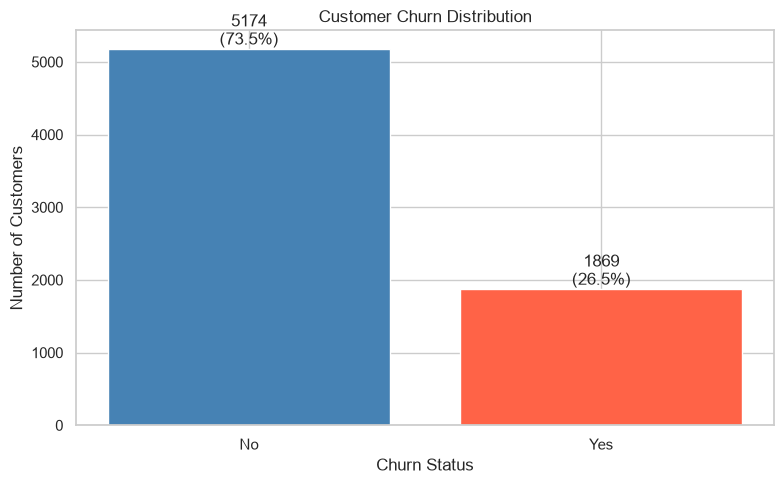

       Customers  Percentage
Churn                       
No          5174       73.46
Yes         1869       26.54


In [24]:
churn_counts = df["Churn"].value_counts().reindex(
    ["No", "Yes"], fill_value=0
)

churn_percent = (
    churn_counts / len(df) * 100
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    churn_counts.index,
    churn_counts.values,
    color=["steelblue", "tomato"]
)

ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn Status")
ax.set_ylabel("Number of Customers")

for bar, percentage in zip(bars, churn_percent):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height())}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("reports/figures/01_churn_distribution.png", dpi=150)
plt.show()

print(pd.DataFrame({
    "Customers": churn_counts,
    "Percentage": churn_percent.round(2)
}))

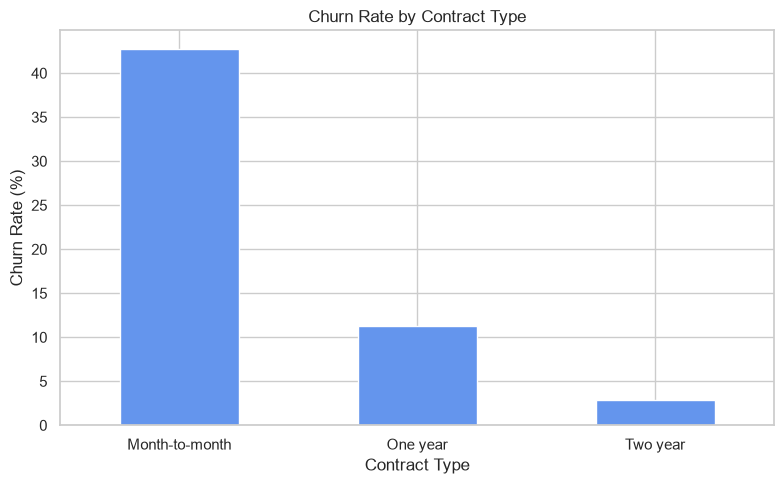

                Total_Customers  Churned_Customers  Churn_Rate
Contract                                                      
Month-to-month             3875               1655       42.71
One year                   1473                166       11.27
Two year                   1695                 48        2.83


In [25]:
contract_summary = (
    df.groupby("Contract", observed=True)
    .agg(
        Total_Customers=("Churn", "size"),
        Churned_Customers=(
            "Churn", lambda x: (x == "Yes").sum()
        )
    )
)

contract_summary["Churn_Rate"] = (
    contract_summary["Churned_Customers"]
    / contract_summary["Total_Customers"] * 100
)

contract_summary = contract_summary.sort_values(
    "Churn_Rate", ascending=False
)

ax = contract_summary["Churn_Rate"].plot(
    kind="bar", figsize=(8, 5), color="cornflowerblue"
)

ax.set_title("Churn Rate by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("reports/figures/02_churn_by_contract.png", dpi=150)
plt.show()

print(contract_summary.round(2))

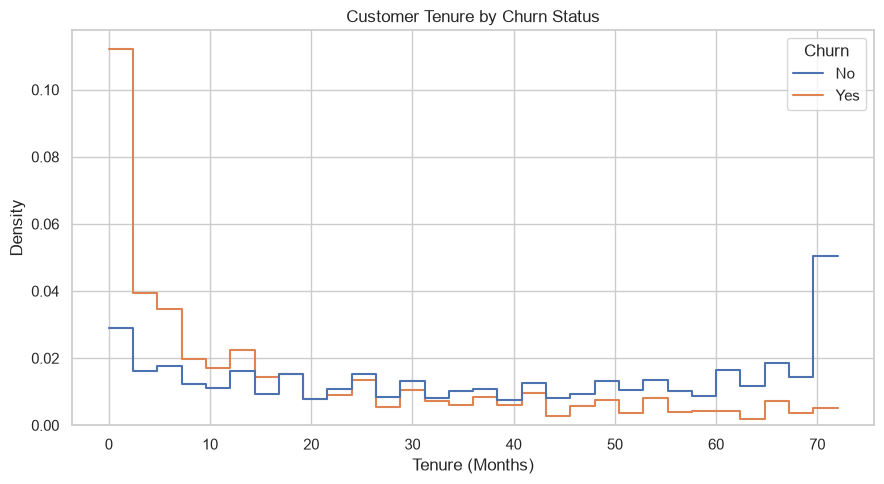

In [26]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    element="step",
    stat="density",
    common_norm=False,
    fill=False,
    ax=ax
)

ax.set_title("Customer Tenure by Churn Status")
ax.set_xlabel("Tenure (Months)")
ax.set_ylabel("Density")

plt.tight_layout()
plt.savefig("reports/figures/03_tenure_distribution.png", dpi=150)
plt.show()

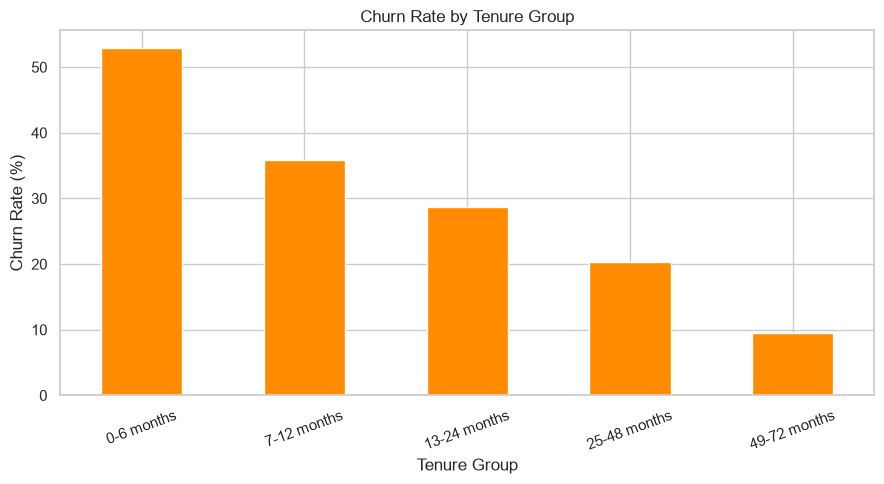

              Total_Customers  Churned_Customers  Churn_Rate
Tenure_Group                                                
0-6 months               1481                784       52.94
7-12 months               705                253       35.89
13-24 months             1024                294       28.71
25-48 months             1594                325       20.39
49-72 months             2239                213        9.51


In [27]:
df["Tenure_Group"] = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=[
        "0-6 months",
        "7-12 months",
        "13-24 months",
        "25-48 months",
        "49-72 months"
    ]
)

tenure_summary = (
    df.groupby("Tenure_Group", observed=True)
    .agg(
        Total_Customers=("Churn", "size"),
        Churned_Customers=(
            "Churn", lambda x: (x == "Yes").sum()
        )
    )
)

tenure_summary["Churn_Rate"] = (
    tenure_summary["Churned_Customers"]
    / tenure_summary["Total_Customers"] * 100
)

tenure_summary["Churn_Rate"].plot(
    kind="bar", figsize=(9, 5), color="darkorange"
)

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig("reports/figures/04_churn_by_tenure.png", dpi=150)
plt.show()

print(tenure_summary.round(2))

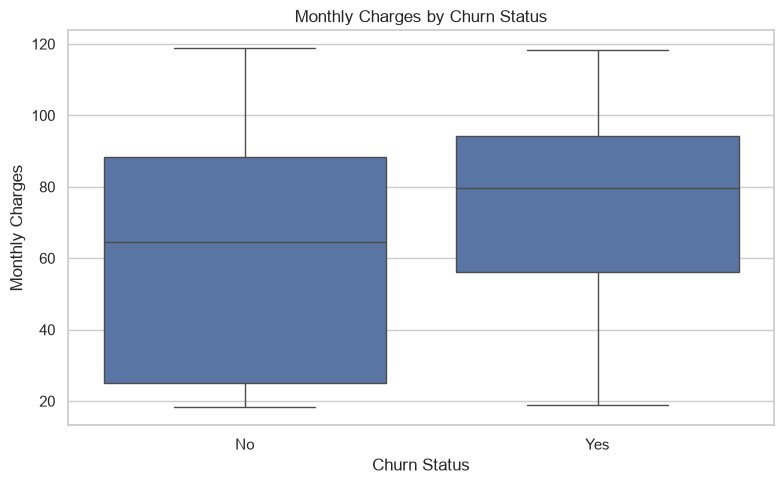

       count   mean  median
Churn                      
No      5174  61.27   64.43
Yes     1869  74.44   79.65


In [28]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    order=["No", "Yes"],
    ax=ax
)

ax.set_title("Monthly Charges by Churn Status")
ax.set_xlabel("Churn Status")
ax.set_ylabel("Monthly Charges")

plt.tight_layout()
plt.savefig("reports/figures/05_monthly_charges.png", dpi=150)
plt.show()

print(
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["count", "mean", "median"])
    .round(2)
)

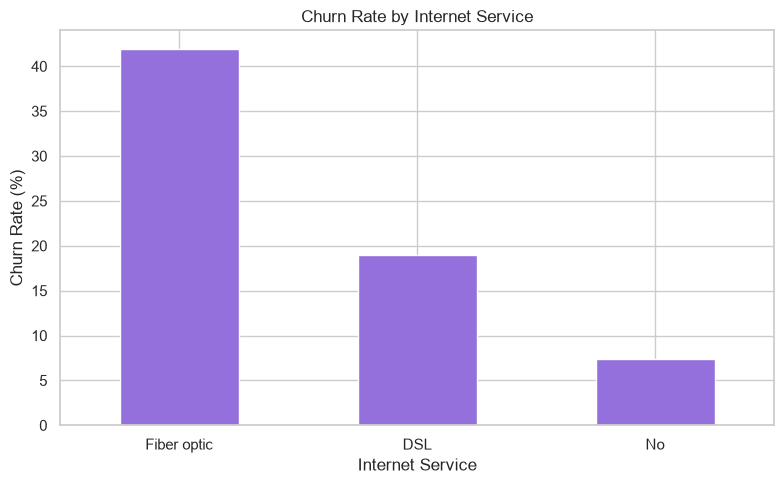

                 Total_Customers  Churned_Customers  Churn_Rate
InternetService                                                
Fiber optic                 3096               1297       41.89
DSL                         2421                459       18.96
No                          1526                113        7.40


In [29]:
internet_summary = (
    df.groupby("InternetService", observed=True)
    .agg(
        Total_Customers=("Churn", "size"),
        Churned_Customers=(
            "Churn", lambda x: (x == "Yes").sum()
        )
    )
)

internet_summary["Churn_Rate"] = (
    internet_summary["Churned_Customers"]
    / internet_summary["Total_Customers"] * 100
)

internet_summary = internet_summary.sort_values(
    "Churn_Rate", ascending=False
)

internet_summary["Churn_Rate"].plot(
    kind="bar", figsize=(8, 5), color="mediumpurple"
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("reports/figures/06_churn_by_internet.png", dpi=150)
plt.show()

print(internet_summary.round(2))

In [30]:
report_dir = Path("reports")
report_dir.mkdir(parents=True, exist_ok=True)

contract_summary.to_csv(
    report_dir / "contract_churn_summary.csv"
)

tenure_summary.to_csv(
    report_dir / "tenure_churn_summary.csv"
)

internet_summary.to_csv(
    report_dir / "internet_churn_summary.csv"
)

print("EDA reports saved successfully!")
print("Charts saved in reports/figures/")

EDA reports saved successfully!
Charts saved in reports/figures/


In [31]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

import pandas as pd
import numpy as np

print("Preprocessing libraries imported successfully.")

Preprocessing libraries imported successfully.


In [32]:
model_df = df.copy()

model_df["TotalCharges"] = pd.to_numeric(
    model_df["TotalCharges"],
    errors="coerce"
)

columns_to_drop = [
    "customerID",
    "Tenure_Group",
    "Monthly_Charge_Group"
]

model_df.drop(
    columns=columns_to_drop,
    errors="ignore",
    inplace=True
)

model_df = model_df.dropna(subset=["Churn"])

X = model_df.drop(columns=["Churn"])
y = model_df["Churn"].map({"No": 0, "Yes": 1})

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining churn proportion:")
print(y_train.mean().round(4))

print("\nTesting churn proportion:")
print(y_test.mean().round(4))

Training features: (5634, 19)
Testing features: (1409, 19)

Training churn proportion:
0.2654

Testing churn proportion:
0.2654


In [34]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\ratne\AppData\Local\Temp\ipykernel_8940\3321186646.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [35]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [36]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (5634, 45)
Processed testing shape: (1409, 45)


In [37]:
%pip install -U scikit-learn xgboost


Note: you may need to restart the kernel to use updated packages.


In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

from xgboost import XGBClassifier
from pathlib import Path

Path("reports/figures").mkdir(parents=True, exist_ok=True)

print("Model training libraries imported successfully.")

Model training libraries imported successfully.


In [39]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print("Model fitting rows:", len(X_fit))
print("Validation rows:", len(X_val))
print("Final test rows:", len(X_test))

print("\nChurn rate:")
print({
    "fit": round(y_fit.mean(), 4),
    "validation": round(y_val.mean(), 4),
    "test": round(y_test.mean(), 4)
})

Model fitting rows: 4507
Validation rows: 1127
Final test rows: 1409

Churn rate:
{'fit': np.float64(0.2654), 'validation': np.float64(0.2653), 'test': np.float64(0.2654)}


In [40]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

pipelines = {
    name: Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", model)
    ])
    for name, model in models.items()
}

print("Pipelines created:", list(pipelines.keys()))

Pipelines created: ['Logistic Regression', 'Random Forest', 'XGBoost']


In [ ]:
validation_results = []
validation_predictions = {}

for name, pipeline in pipelines.items():
    print(f"Training {name}...")

    pipeline.fit(X_fit, y_fit)

    y_pred = pipeline.predict(X_val)
    y_proba = pipeline.predict_proba(X_val)[:, 1]

    validation_predictions[name] = {
        "pred": y_pred,
        "proba": y_proba
    }

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_val, y_proba)
    })

validation_df = pd.DataFrame(validation_results)
validation_df = validation_df.sort_values(
    "ROC_AUC", ascending=False
).reset_index(drop=True)

display(
    validation_df.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}",
        "ROC_AUC": "{:.3f}"
    })
)

Training Logistic Regression...
Training Random Forest...
Training XGBoost...


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,XGBoost,0.807,0.697,0.485,0.572,0.850
1,Logistic Regression,0.815,0.694,0.545,0.610,0.848
2,Random Forest,0.770,0.551,0.722,0.625,0.841


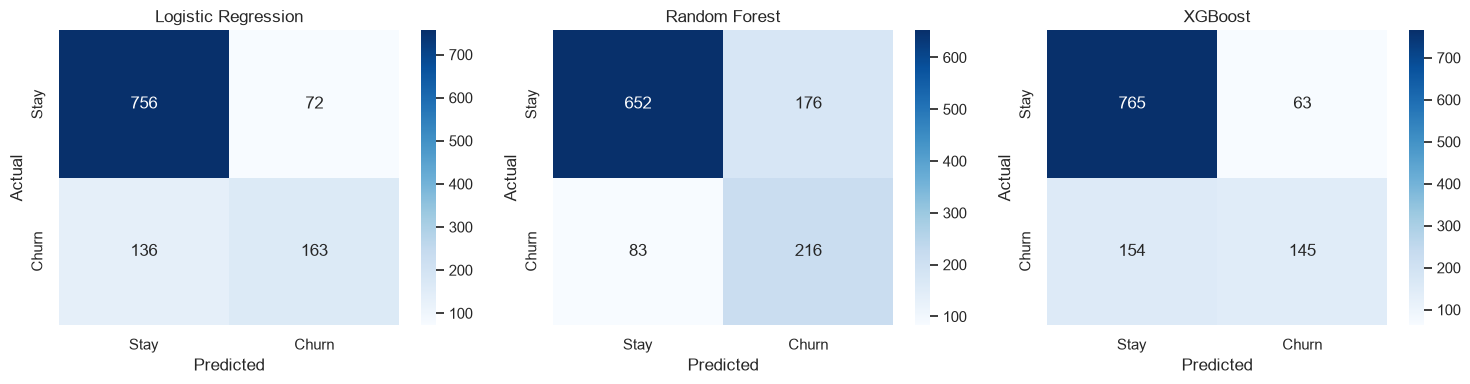

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, result) in zip(
    axes, validation_predictions.items()
):
    cm = confusion_matrix(
        y_val,
        result["pred"],
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Stay", "Churn"],
        yticklabels=["Stay", "Churn"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig(
    "reports/figures/08_validation_confusion_matrices.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

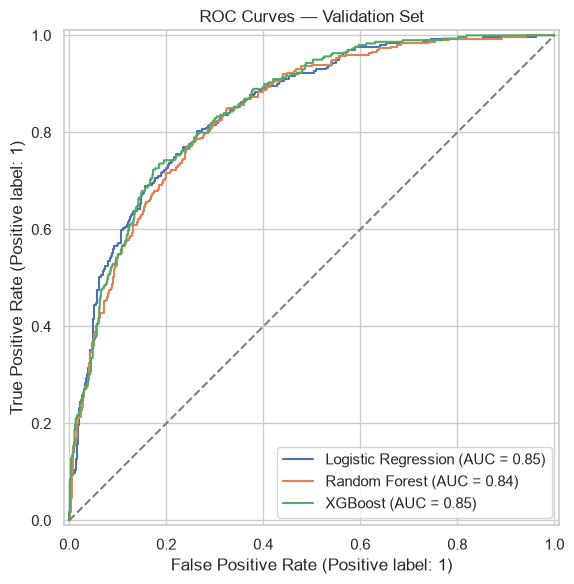

In [43]:
fig, ax = plt.subplots(figsize=(9, 6))

for name, result in validation_predictions.items():
    RocCurveDisplay.from_predictions(
        y_val,
        result["proba"],
        name=name,
        ax=ax
    )

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random ranking"
)

ax.set_title("ROC Curves — Validation Set")
plt.tight_layout()
plt.savefig(
    "reports/figures/09_validation_roc_curves.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [44]:
best_model_name = validation_df.iloc[0]["Model"]
best_validation_auc = validation_df.iloc[0]["ROC_AUC"]

print("Top model by validation ROC-AUC:", best_model_name)
print(f"Validation ROC-AUC: {best_validation_auc:.4f}")

print("\nValidation metrics for the top model:")
print(
    validation_df.loc[
        validation_df["Model"] == best_model_name
    ].to_string(index=False)
)

Top model by validation ROC-AUC: XGBoost
Validation ROC-AUC: 0.8503

Validation metrics for the top model:
  Model  Accuracy  Precision  Recall       F1  ROC_AUC
XGBoost  0.807453   0.697115 0.48495 0.571992  0.85026


In [45]:
final_pipeline = pipelines[best_model_name]

final_pipeline.fit(X_train, y_train)

y_test_pred = final_pipeline.predict(X_test)
y_test_proba = final_pipeline.predict_proba(X_test)[:, 1]

test_metrics = {
    "Model": best_model_name,
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(
        y_test, y_test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_test_pred, zero_division=0
    ),
    "F1": f1_score(
        y_test, y_test_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test, y_test_proba)
}

test_results_df = pd.DataFrame([test_metrics])

display(
    test_results_df.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}",
        "ROC_AUC": "{:.3f}"
    })
)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1],
        target_names=["Stay", "Churn"],
        zero_division=0
    )
)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,XGBoost,0.796,0.646,0.513,0.572,0.842



Classification report:
              precision    recall  f1-score   support

        Stay       0.84      0.90      0.87      1035
       Churn       0.65      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



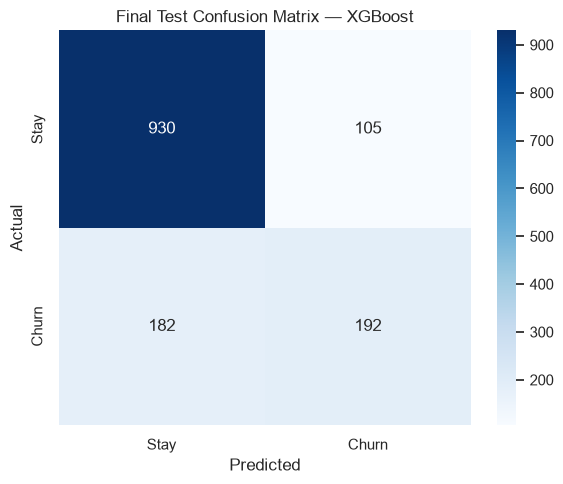

In [46]:
fig, ax = plt.subplots(figsize=(6, 5))

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stay", "Churn"],
    yticklabels=["Stay", "Churn"],
    ax=ax
)

ax.set_title(f"Final Test Confusion Matrix — {best_model_name}")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig(
    "reports/figures/10_final_test_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

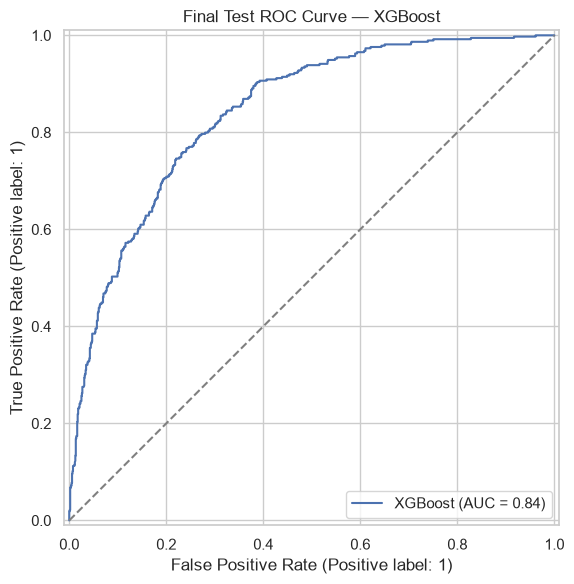

In [47]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    y_test_proba,
    name=best_model_name,
    ax=ax
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray"
)

ax.set_title(f"Final Test ROC Curve — {best_model_name}")

plt.tight_layout()
plt.savefig(
    "reports/figures/11_final_test_roc_curve.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [48]:
Path("reports").mkdir(exist_ok=True)

validation_df.to_csv(
    "reports/validation_model_comparison.csv",
    index=False
)

test_results_df.to_csv(
    "reports/final_test_metrics.csv",
    index=False
)

print("Evaluation reports saved successfully.")

Evaluation reports saved successfully.


In [53]:
from pathlib import Path
import joblib
import json
import sklearn
import xgboost

# Create model directory
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Model directory ready:", MODEL_DIR.resolve())

Model directory ready: C:\Users\ratne\customer-churn-prediction\notebooks\models


In [59]:
model_path = MODEL_DIR / "churn_pipeline.joblib"

joblib.dump(final_pipeline, model_path)

print("Model saved successfully!")
print("Path:", model_path.resolve())
print("Selected model:", best_model_name)

Model saved successfully!
Path: C:\Users\ratne\customer-churn-prediction\notebooks\models\churn_pipeline.joblib
Selected model: XGBoost


In [60]:
metadata = {
    "project": "Customer Churn Prediction",
    "dataset": "IBM Telco Customer Churn",
    "selected_model": best_model_name,
    "target": "Churn",
    "target_mapping": {
        "No": 0,
        "Yes": 1
    },
    "features": X_train.columns.tolist(),
    "test_metrics": {
        key: float(value)
        for key, value in test_metrics.items()
        if key != "Model"
    },
    "versions": {
        "scikit_learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
        "joblib": joblib.__version__
    }
}

metadata_path = MODEL_DIR / "metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

print("Metadata saved:", metadata_path.resolve())

Metadata saved: C:\Users\ratne\customer-churn-prediction\notebooks\models\metadata.json


In [61]:
# Reload saved pipeline
loaded_pipeline = joblib.load(
    "models/churn_pipeline.joblib"
)

# Predict on a few test customers
sample_customers = X_test.head(5)

sample_predictions = loaded_pipeline.predict(
    sample_customers
)

sample_probabilities = loaded_pipeline.predict_proba(
    sample_customers
)[:, 1]

verification_df = pd.DataFrame({
    "Predicted_Churn": sample_predictions,
    "Churn_Probability": sample_probabilities
}, index=sample_customers.index)

verification_df["Predicted_Churn"] = (
    verification_df["Predicted_Churn"]
    .map({0: "No", 1: "Yes"})
)

display(verification_df)

,Predicted_Churn,Churn_Probability
437,No,0.011494
2280,Yes,0.919548
2235,No,0.084027
4460,No,0.349581
3761,No,0.008467


In [62]:
original_predictions = final_pipeline.predict(sample_customers)
reloaded_predictions = loaded_pipeline.predict(sample_customers)

assert np.array_equal(
    original_predictions,
    reloaded_predictions
), "Predictions do not match!"

original_probabilities = final_pipeline.predict_proba(
    sample_customers
)[:, 1]

reloaded_probabilities = loaded_pipeline.predict_proba(
    sample_customers
)[:, 1]

assert np.allclose(
    original_probabilities,
    reloaded_probabilities
), "Probabilities do not match!"

print("Model verification successful!")

Model verification successful!
